### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [3]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [4]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    df = pd.DataFrame(np.array(data[1].data).byteswap().view(np.array(data[1].data).dtype.newbyteorder()))
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [5]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [6]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [7]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [18]:
X = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [19]:
Y = df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [20]:
model = RandomForestRegressor()

In [21]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [22]:
%%time
# Evaluamos el modelo dividiendo los datos en 5 partes (cv=5)
scores = cross_validate(model, X, y, cv=5)

# Mostramos el rendimiento (R^2 por defecto) en cada uno de los 5 cortes
print("Scores en cada fold:", scores['test_score'])
print("Score promedio:", scores['test_score'].mean())

Scores en cada fold: [0.24588718 0.34581746 0.25818915 0.30387326 0.28716298]
Score promedio: 0.28818600593192784
CPU times: user 1min 20s, sys: 675 ms, total: 1min 21s
Wall time: 1min 21s


In [23]:
scores

{'fit_time': array([16.15215087, 15.59138274, 16.01735187, 15.9906044 , 16.62789011]),
 'score_time': array([0.24136448, 0.23271704, 0.24393702, 0.23623943, 0.23899817]),
 'test_score': array([0.24588718, 0.34581746, 0.25818915, 0.30387326, 0.28716298])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [24]:

scores_r2 = scores['test_score']


promedio = np.mean(scores_r2)
desviacion_estandar = np.std(scores_r2)

print(promedio)
print(desviacion_estandar)

0.28818600593192784
0.03537661357726585


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

El modelo presenta un posible sesgo alto, ya que el R² promedio es de 0,2882, lo que indica que explica solo el 28,82 % de la variabilidad de los datos. En cambio, la varianza parece relativamente baja, porque la desviación estándar es de 0,0354 y los resultados son similares entre las particiones

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [26]:
ypred = cross_val_predict(model, X, y, cv=5)

(0.0, 3.0)

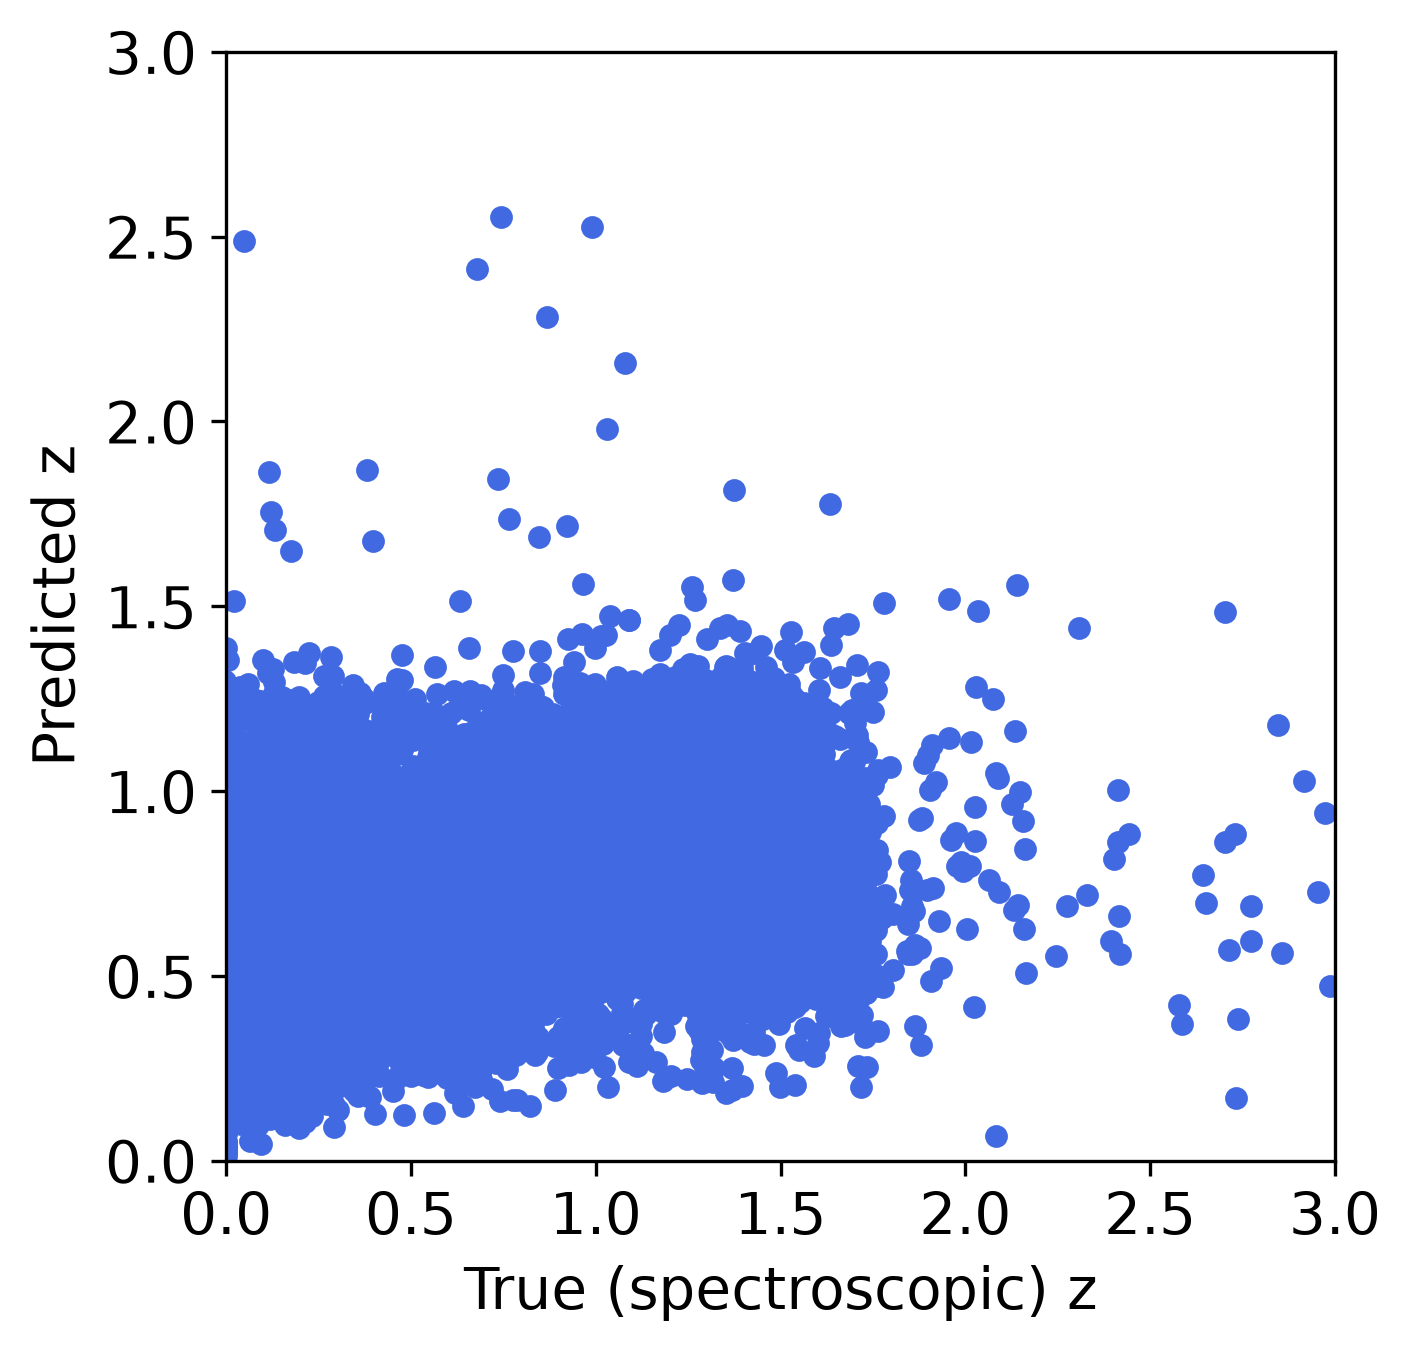

In [27]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

Se parece poco, pero el gráfico muestra que las predicciones se concentran entre 0 y 1,3, incluso para galaxias con redshifts espectroscópicos mayores. Esto indica que el modelo tiende a subestimar los redshifts altos y presenta una dispersión considerable, por lo que sus predicciones no son muy precisas.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

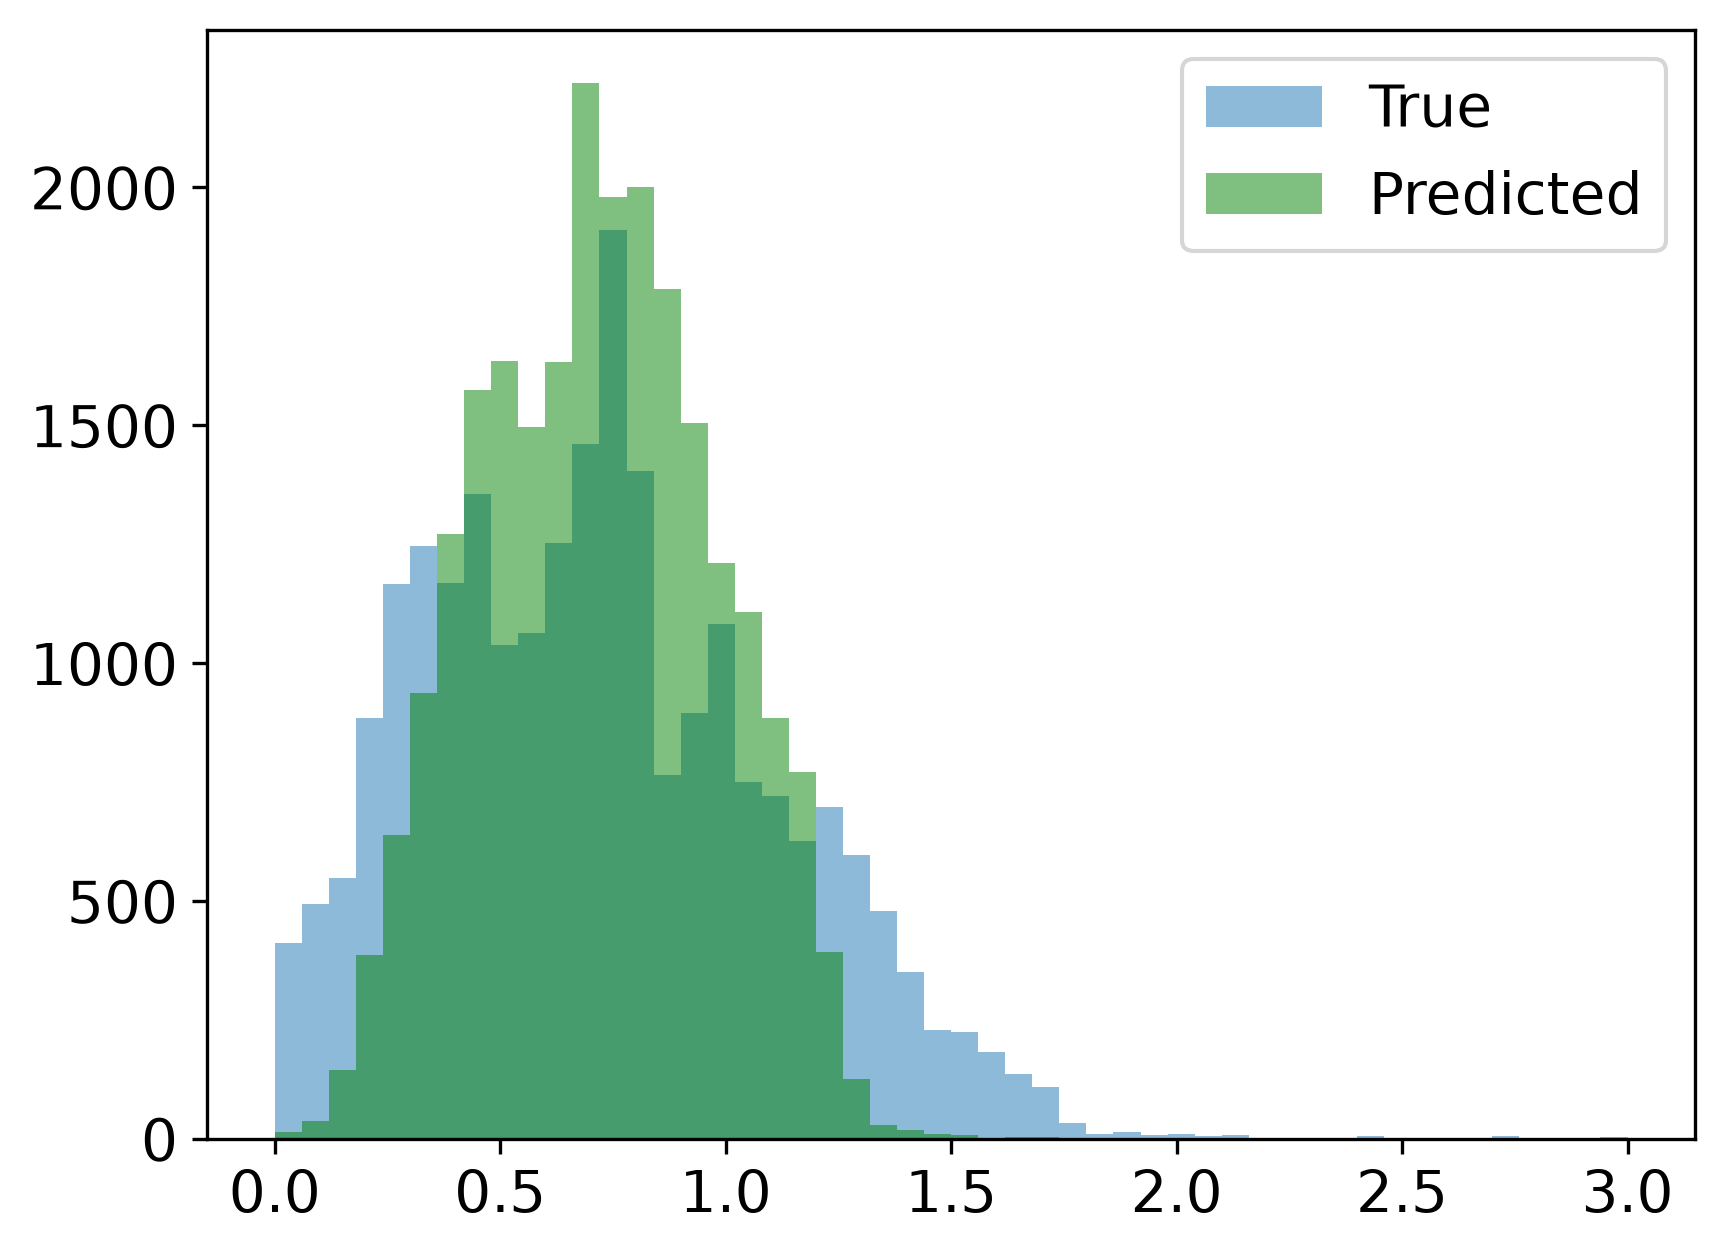

In [28]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [29]:
delta_z = (ypred - target) / (1 + target)

sigma_NMAD = 1.48 * np.median(np.abs(delta_z - np.median(delta_z)))
eta = np.mean(np.abs(delta_z) > 0.15)

print("Sigma NMAD:", sigma_NMAD)
print("Fracción de outliers:", eta)
print("Porcentaje de outliers:", eta * 100, "%")

Sigma NMAD: 0.0764721209156
Fracción de outliers: 0.2607253799009319
Porcentaje de outliers: 26.072537990093192 %


y NMAD

In [33]:
NMAD = np.median(np.abs(delta_z - np.median(delta_z)))


print("NMAD:", NMAD)


NMAD: 0.05167035197000001


En comparación con Zhou et al. (2019), nuestro modelo presenta un rendimiento inferior, con un \(\sigma_{\mathrm{NMAD}}=0{,}0765\) y un 26,07 % de outliers, lo que indica una mayor dispersión y errores en las predicciones de los redshifts fotométricos

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [34]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [35]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [36]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [38]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [40]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.2810026883980138), np.float64(0.8745473860144466))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [41]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [43]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}
#... implemente el resto
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=10)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True,
    verbose=2
)

grid_search.fit(seld, selt)

print("Mejores parámetros:")
print(grid_search.best_params_)

print("Mejor R² promedio en validación:")
print(grid_search.best_score_)

print("R² promedio de entrenamiento:")
print(grid_search.cv_results_['mean_train_score'][grid_search.best_index_])

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Mejores parámetros:
{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 20, 'n_estimators': 200}
Mejor R² promedio en validación:
0.3008896434878322
R² promedio de entrenamiento:
0.6524967614332018
CPU times: user 20 s, sys: 452 ms, total: 20.4 s
Wall time: 3min 40s


El mejor modelo obtuvo un \(R^2=0{,}3009\) en validación cruzada, lo que indica una capacidad predictiva limitada. En comparación, Zhou et al. (2019) reportaron una precisión de redshift fotométrico de aproximadamente 2 % o mejor en la región más profunda de su muestra, utilizando Random Forest y fotometría corregida de apertura

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [49]:
scores = pd.DataFrame(grid_search.cv_results_)

scoresCV = scores[['params', 'mean_test_score', 'std_test_score', 'mean_train_score']].sort_values(
    by='mean_test_score',
    ascending=False
)



In [50]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300890,0.031821,0.652497
100,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.300361,0.032585,0.753081
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298122,0.035280,0.726939
185,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.297736,0.031401,0.622079
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.297467,0.033173,0.752794
...,...,...,...,...
135,"{'max_features': 4, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.000291,0.000217,-0.000005
42,"{'max_features': None, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000291,0.000203,-0.000006
15,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.5, 'min_samples_split'...",-0.000294,0.000198,-0.000004
66,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000295,0.000178,-0.000005


### Mejoran los scores?
La optimización de hiperparámetros mejoró el R2 promedio de validación de 0,2810 a 0,3009. Asimismo, el score de entrenamiento disminuyó de 0,8745 a 0,6525, lo que sugiere una reducción del sobreajuste.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [51]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [52]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [53]:
mags.shape

(23822, 9)

In [54]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [55]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [56]:
mags = mags[mags > -10].dropna()

In [57]:
mags.shape

(6371, 9)

In [59]:
mags = mags[mags < 90].dropna()

In [60]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [61]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [63]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [ ]:
scores_new = cross_validate()

In [64]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.ensemble import RandomForestRegressor

model_new = RandomForestRegressor(random_state=20)

cv = KFold(n_splits=5, shuffle=True, random_state=10)

scores_new = cross_validate(
    model_new,
    sel_features,
    sel_target,
    cv=cv,
    return_train_score=True
)

print("R² promedio de validación:", scores_new['test_score'].mean())
print("Desviación estándar:", scores_new['test_score'].std())
print("R² promedio de entrenamiento:", scores_new['train_score'].mean())

R² promedio de validación: 0.7453475658272517
Desviación estándar: 0.10321608097177354
R² promedio de entrenamiento: 0.9634846325251708


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

los resultados mejoran norablemente tras filtrar los datos y el modelo explica aproximadamente el 74,5 % de la variabilidad del redshift en validación cruzada, frente al 30,1 % del modelo optimizado anterior. Sin embargo, la diferencia entre entrenamiento y validación todavía sugiere cierto sobreajuste modelo explica aproximadamente el 74,5 % de la variabilidad del redshift en validación cruzada, frente al 30,1 % del modelo optimizado anterior. Sin embargo, la diferencia entre entrenamiento y validación todavía sugiere cierto sobreajuste

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



In [67]:
colors = pd.DataFrame(index=sel_features.index)

colors['u-g'] = sel_features['u_apercor'] - sel_features['g_apercor']
colors['g-r'] = sel_features['g_apercor'] - sel_features['r_apercor']
colors['r-i'] = sel_features['r_apercor'] - sel_features['i_apercor']
colors['i-z'] = sel_features['i_apercor'] - sel_features['z_apercor']
colors['z-y'] = sel_features['z_apercor'] - sel_features['y_apercor']

colors['i'] = sel_features['i_apercor']

colors.head()

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [68]:
model_colors = RandomForestRegressor(random_state=20)

scores_colors = cross_validate(
    model_colors,
    colors,
    sel_target,
    cv=cv,
    return_train_score=True
)

print("R² promedio de validación:", scores_colors['test_score'].mean())
print("Desviación estándar:", scores_colors['test_score'].std())
print("R² promedio de entrenamiento:", scores_colors['train_score'].mean())

R² promedio de validación: 0.8113917710674869
Desviación estándar: 0.08084385263187324
R² promedio de entrenamiento: 0.9716740142564102


In [69]:
from sklearn.model_selection import cross_val_predict

ypred_cv = cross_val_predict(
    model_colors,
    colors,
    sel_target,
    cv=cv,
    n_jobs=-1
)

delta_z = (ypred_cv - sel_target) / (1 + sel_target)

NMAD = np.median(np.abs(delta_z - np.median(delta_z)))
sigma_NMAD = 1.48 * NMAD
eta = np.mean(np.abs(delta_z) > 0.15)

print("Sigma NMAD:", sigma_NMAD)
print("Fracción de outliers:", eta)
print("Porcentaje de outliers:", eta * 100)

Sigma NMAD: 0.016273344385935303
Fracción de outliers: 0.035991755192643096
Porcentaje de outliers: 3.5991755192643096


Al usar los colores fotométricos junto con la magnitud i, el modelo mejoró bastante, alcanzando un R2=0,8114. Además, obtuvimos un sigmaNMAD=0,0163 y un 3,60 % de outliers, resultados mejores que los valores de referencia de Zhou et al. (2019), que fueron 0,018 y 4,7 %, respectivamente. Esto sugiere que los colores ayudan a estimar mejor los redshifts